# Instrumented trajectory generation

Run all cells to generate instruments, feed them directly into the trajectory generator, and inspect the resulting trajectory. No CSV files are needed.

`instruments`, `result`, and `trajectory` stay in the notebook kernel. Saved plots remain visible after closing the notebook; restart the kernel and **Run All** to recreate the data from the seeds. The hidden distribution is fixed within a run. Use the same `DISTRIBUTION_SEED` across runs to keep the law fixed while changing `TRAJECTORY_SEED` to sample new disturbances.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "controls" / "scenarios" / "instrumented.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from controls.scenarios.instruments import generateInstruments
from controls.scenarios.instrumented import generateTrajectory
from controls.ScenarioGenerator import ScenarioGenerator

No event loop hook running.


In [2]:
DURATION = 20.0
DT = 0.1
INSTRUMENT_SEED = 42
TRAJECTORY_SEED = 123
DISTRIBUTION_SEED = 7

# These control the black-box generator, not an estimator.
ALPHA, BETA, GAMMA, DELTA = 1.0, 0.5, 0.3, 0.8
INPUT_NOISE_STDDEV = 0.2

In [3]:
# The external instrument process runs first.
instruments = generateInstruments(duration=DURATION, dt=DT, seed=INSTRUMENT_SEED)

# The trajectory generator consumes its samples directly, without writing a file.
result = generateTrajectory(
    instruments, seed=TRAJECTORY_SEED, distributionSeed=DISTRIBUTION_SEED,
    alpha=ALPHA, beta=BETA, gamma=GAMMA, delta=DELTA,
    inputNoiseStddev=INPUT_NOISE_STDDEV,
)
trajectory = result.scenario

# Ready for the existing simulation API whenever you want it.
scenario_generator = ScenarioGenerator(trajectory)

# Convenient arrays for exploration and later estimator work.
time = np.arange(len(trajectory.states)) * trajectory.dt
states = np.array([[s.position.x, s.position.y, s.xdot, s.ydot] for s in trajectory.states])
input_time = time[:-1]
z = np.array([[s.z_x, s.z_y] for s in instruments])
u = np.array(result.inputs)
print(f"{len(instruments)} input intervals → {len(states)} states; duration {time[-1]:g} s")
print("State columns: x, y, vx, vy")
print(states[:5])

200 input intervals → 201 states; duration 20 s
State columns: x, y, vx, vy
[[ 2.          2.          0.          0.        ]
 [ 2.          2.          0.05785561 -0.15995524]
 [ 2.00578556  1.98400448  0.11207041 -0.17491958]
 [ 2.0169926   1.96651252 -0.01117567 -0.26431461]
 [ 2.01587503  1.94008106 -0.01520449 -0.24919646]]


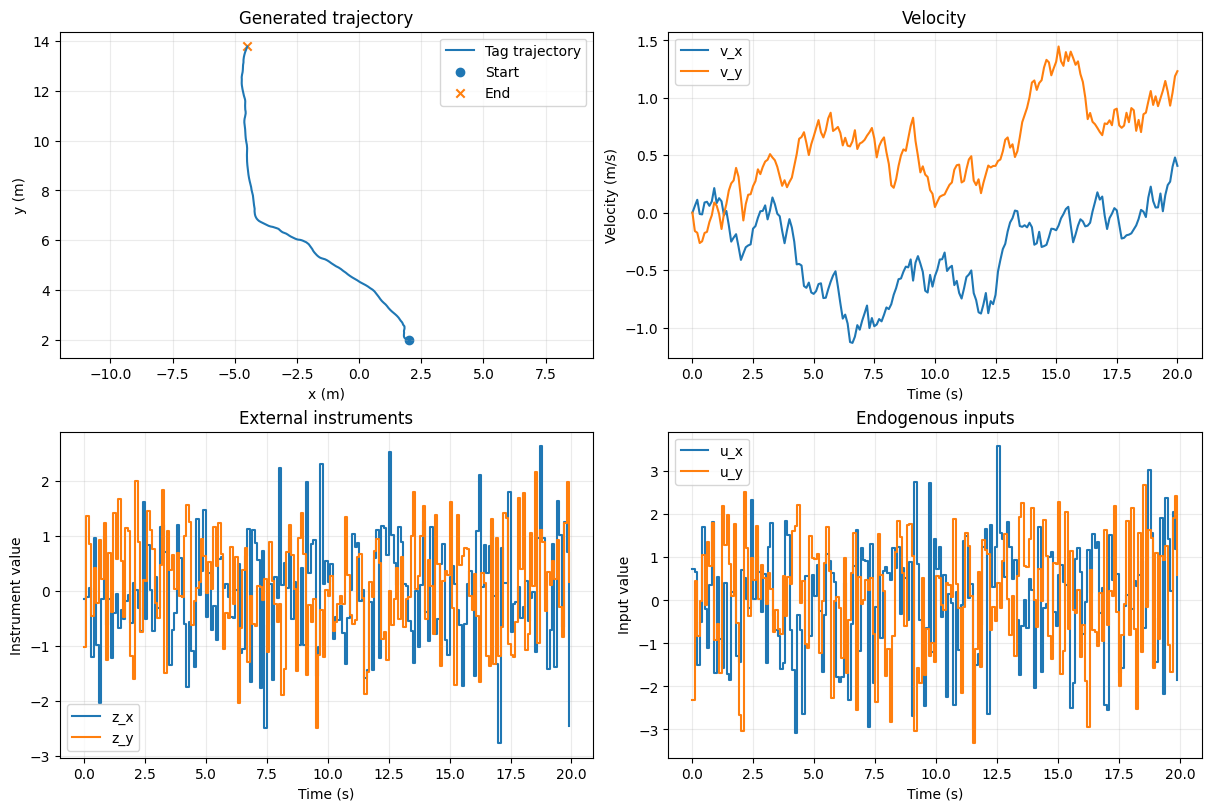

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
ax = axes[0, 0]
ax.plot(states[:, 0], states[:, 1], label="Tag trajectory")
ax.scatter(*states[0, :2], marker="o", label="Start")
ax.scatter(*states[-1, :2], marker="x", label="End")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Generated trajectory")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
for axis, label in enumerate(("x", "y")):
    axes[0, 1].plot(time, states[:, axis + 2], label=f"v_{label}")
    axes[1, 0].step(input_time, z[:, axis], where="post", label=f"z_{label}")
    axes[1, 1].step(input_time, u[:, axis], where="post", label=f"u_{label}")
axes[0, 1].set(xlabel="Time (s)", ylabel="Velocity (m/s)", title="Velocity")
axes[1, 0].set(xlabel="Time (s)", ylabel="Instrument value", title="External instruments")
axes[1, 1].set(xlabel="Time (s)", ylabel="Input value", title="Endogenous inputs")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Hidden truth: evaluation only

`result.truth` retains the coefficients, chosen mixture law, and latent disturbance draws. These are useful to assess a future estimator, but must not be supplied to it as observations. The cell below compares sampled disturbances with their actual density; a finite trajectory's histogram will not match the density exactly.

This first version uses iid disturbances from a stationary law, independent across axes. It does not yet make the distribution depend on state or time. Positions are unbounded, and the supplied equations use forward Euler with acceleration noise multiplied by `DT`.

True coefficients: {'alpha': 1.0, 'beta': 0.5, 'gamma': 0.3, 'delta': 0.8}
Hidden mixture: {'family': 'two_component_gaussian_mixture', 'probability': 0.701743255930235, 'means': (0.6472307631634322, -1.5228149307976038), 'stddevs': (0.11545360368632038, 0.12990815449527032), 'mean': 0, 'variance': 1, 'iidAcrossTimeAndAxes': True}


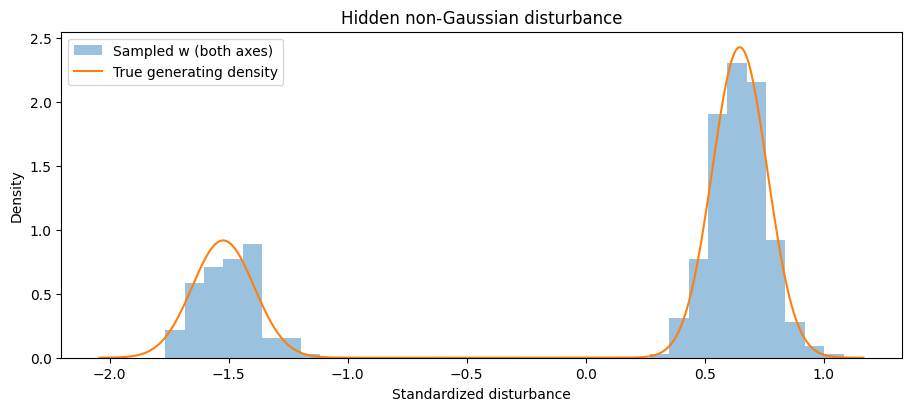

In [5]:
truth = result.truth
law = truth["disturbance"]
w = np.array([row["w"] for row in truth["latentDraws"]])
nu = np.array([row["nu"] for row in truth["latentDraws"]])
print("True coefficients:", truth["coefficients"])
print("Hidden mixture:", law)

grid = np.linspace(min(w.min(), min(law["means"]) - 4 * max(law["stddevs"])),
                   max(w.max(), max(law["means"]) + 4 * max(law["stddevs"])), 600)
density = np.zeros_like(grid)
for probability, mean, sigma in zip((law["probability"], 1 - law["probability"]), law["means"], law["stddevs"]):
    density += probability * np.exp(-0.5 * ((grid - mean) / sigma)**2) / (sigma * np.sqrt(2 * np.pi))
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.hist(w.ravel(), bins=35, density=True, alpha=0.45, label="Sampled w (both axes)")
ax.plot(grid, density, label="True generating density")
ax.set(xlabel="Standardized disturbance", ylabel="Density", title="Hidden non-Gaussian disturbance")
ax.legend()
plt.show()

## Black-box motion: system and noise separately

The motion distribution is a **transition distribution**, not the histogram of visited positions. In this generator, position updates deterministically from the current velocity. Velocity changes according to:

\[
\frac{\mathbf v_{t+1}-\mathbf v_t}{\Delta t}
=\underbrace{\beta\alpha\mathbf z_t}_{\text{system response given the instrument}}
+\underbrace{(\beta\delta+\gamma)\mathbf w_t+\beta\boldsymbol\nu_t}_{\text{effective motion noise}}.
\]

This separation puts all hidden randomness into the noise term. Separating the original terms as `beta*u` and `gamma*w` is also algebraically valid, but those terms are correlated because `u` contains `w`.

The left plots show the system response across this run's supplied instrument values. **At a fixed instrument value, that response is deterministic.** The right plots show effective noise samples and their exact generating density, a Gaussian mixture obtained by scaling w and adding independent Gaussian nu. Conditional acceleration has that same noise density shifted by `beta*alpha*z_t`; conditional next velocity additionally scales it by `DT` and shifts it by the current velocity. These are per-axis views; the generator draws noise independently across axes.

Everything in this cell uses ground truth for inspection, not estimator observations.

Effective-noise mixture weights: [0.70174326 0.29825674]
Effective-noise component means: [ 0.45306153 -1.06597045]
Effective-noise component standard deviations: [0.12857477 0.13516399]
True noise mean: 0; per-axis variance: 0.49999999999999994


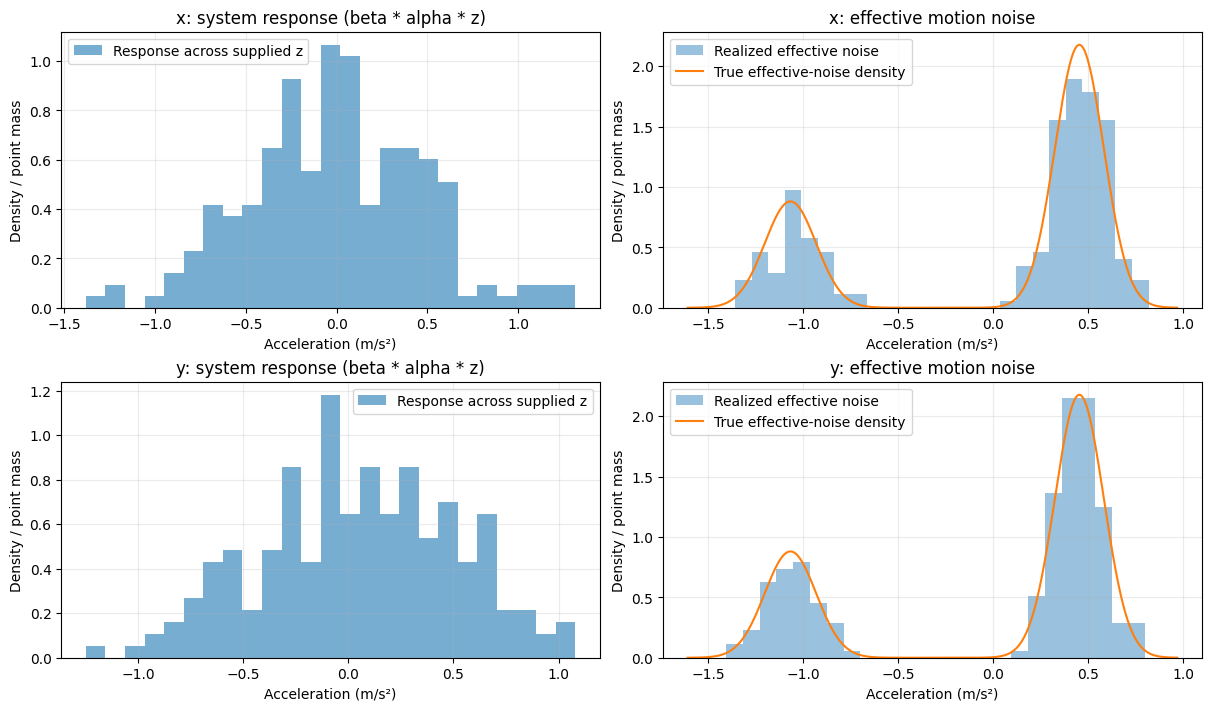

In [6]:
# Reconstruct the actual motion components from the generated result.
coefficients = result.truth["coefficients"]
alpha, beta, gamma, delta = (coefficients[key] for key in ("alpha", "beta", "gamma", "delta"))
noise_law = result.truth["disturbance"]
latent_w = np.array([row["w"] for row in result.truth["latentDraws"]])
latent_nu = np.array([row["nu"] for row in result.truth["latentDraws"]])
system_acceleration = beta * alpha * z
motion_noise = (beta * delta + gamma) * latent_w + beta * latent_nu
actual_acceleration = np.diff(states[:, 2:], axis=0) / trajectory.dt

# The two components sum to the realized acceleration in both axes.
assert np.allclose(system_acceleration + motion_noise, actual_acceleration)

# Exact effective-noise law: linear transform of each w mixture component,
# convolved with beta*nu. Independent Gaussian variances add.
noise_probabilities = np.array([noise_law["probability"], 1 - noise_law["probability"]])
noise_means = (beta * delta + gamma) * np.array(noise_law["means"])
noise_sigmas = np.sqrt(
    ((beta * delta + gamma) * np.array(noise_law["stddevs"]))**2
    + (beta * result.truth["inputNoise"]["stddev"])**2
)
noise_lower = min(motion_noise.min(), (noise_means - 4 * noise_sigmas).min())
noise_upper = max(motion_noise.max(), (noise_means + 4 * noise_sigmas).max())
if noise_lower == noise_upper:
    noise_lower, noise_upper = noise_lower - 1, noise_upper + 1
noise_grid = np.linspace(noise_lower, noise_upper, 800)
noise_density = np.zeros_like(noise_grid)
for probability, mean, sigma in zip(noise_probabilities, noise_means, noise_sigmas):
    if sigma > 0:
        noise_density += probability * np.exp(-0.5 * ((noise_grid - mean) / sigma)**2) / (sigma * np.sqrt(2 * np.pi))

fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for axis, name in enumerate(("x", "y")):
    system_ax, noise_ax = axes[axis]
    response = system_acceleration[:, axis]
    if np.ptp(response) == 0:
        system_ax.axvline(response[0], label="Deterministic response (point mass)")
    else:
        system_ax.hist(response, bins=25, density=True, alpha=0.6, label="Response across supplied z")
    if np.any(noise_sigmas > 0):
        noise_ax.hist(motion_noise[:, axis], bins=25, density=True, alpha=0.45, label="Realized effective noise")
        noise_ax.plot(noise_grid, noise_density, label="True effective-noise density")
    else:
        # A zero-noise configuration has probability masses, not a density.
        for probability, mean in zip(noise_probabilities, noise_means):
            noise_ax.axvline(mean, alpha=0.7, label=f"Point mass: weight {probability:.2f}")
    system_ax.set(title=f"{name}: system response (beta * alpha * z)", xlabel="Acceleration (m/s²)", ylabel="Density / point mass")
    noise_ax.set(title=f"{name}: effective motion noise", xlabel="Acceleration (m/s²)", ylabel="Density / point mass")
    for ax in (system_ax, noise_ax):
        ax.grid(alpha=0.25)
        ax.legend()
plt.show()

print("Effective-noise mixture weights:", noise_probabilities)
print("Effective-noise component means:", noise_means)
print("Effective-noise component standard deviations:", noise_sigmas)
print("True noise mean: 0; per-axis variance:", (beta * delta + gamma)**2 + (beta * result.truth["inputNoise"]["stddev"])**2)